### Խնդրի սահմանում՝ Հաճախորդների սեգմենտավորում (K-Means և Գրաֆային մոտեցումներով)

Տրված է $N$ կետերից բաղկացած բազմություն, որտեղ յուրաքանչյուր $i$-րդ կետ նկարագրվում է իր կոորդինատների վեկտորով՝ $\mathbf{x}_i \in \mathbb{R}^d$։


Նպատակը. Բաժանել տրված կետերը $K$ չհատվող խմբերի (կլաստերների)՝ $\{C_1, C_2, \dots, C_K\}$, այնպես, որ նույն խմբի ներսում գտնվող կետերը լինեն հնարավորինս մոտ կամ փոխկապակցված միմյանց, իսկ տարբեր խմբերի կետերը՝ հնարավորինս հեռու։   Տարածական մոտեցում (K-Means ալգորիթմ). Կետերը դիտարկվում են $d$-չափանի Էվկլիդյան տարածության մեջ։ Խնդիրը հանգում է $K$ կենտրոնների՝ $\{\boldsymbol{\mu}_1, \dots, \boldsymbol{\mu}_K\}$ ընտրությանը, որոնք կմինիմալացնեն կետերի և իրենց համապատասխան կենտրոնների միջև հեռավորությունների քառակուսիների գումարը (WCSS).

   $$\min_{\{C_1, \dots, C_K\}} \sum_{k=1}^{K} \sum_{\mathbf{x}_i \in C_k} \Vert{}\mathbf{x}_i - \boldsymbol{\mu}_k\Vert{}^2$$  
 Նմանության գրաֆի մոտեցում (Graph / Spectral Clustering). Կառուցվում է չուղղորդված կշռված գրաֆ՝ $G = (V, E, W)$, որտեղ գագաթները ($V$) տրված կետերն են, իսկ կողերի կշիռները՝ $w_{ij} = \exp\left(-\frac{\Vert{}\mathbf{x}_i - \mathbf{x}_j\Vert{}^2}{2\sigma^2}\right)$ (ցույց է տալիս կետերի մոտիկության աստիճանը)։ Խնդիրը գրաֆը $K$ ենթագրաֆների բաժանելն է՝ մինիմալացնելով խմբերի միջև կտրված կողերի կշիռները (Normalized Cut)։

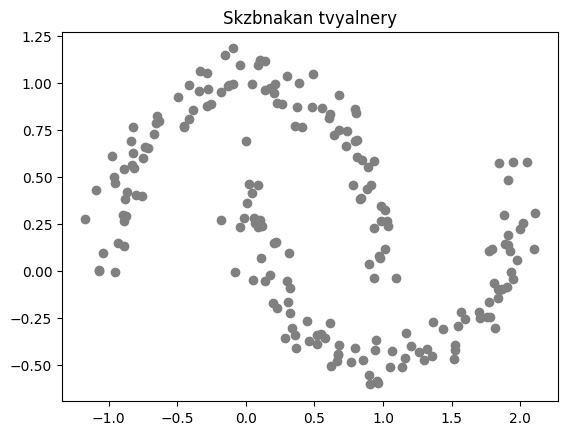

In [8]:
import random
import math
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_moons

X, true_labels = make_moons(n_samples=200, noise=0.08, random_state=42)
data = X.tolist()

plt.scatter(X[:, 0], X[:, 1], color='gray')
plt.title("Skzbnakan tvyalnery")
plt.show()

In [11]:
true_labels[:10],X[:10]

(array([0, 0, 0, 1, 1, 1, 0, 1, 1, 0]),
 array([[-1.03793155,  0.0928726 ],
        [ 0.91602113,  0.45763611],
        [ 0.64144066,  0.72259255],
        [ 1.20444693, -0.40199089],
        [ 0.30530111, -0.16542521],
        [ 0.22358098,  0.15315954],
        [-0.65050818,  0.82072755],
        [ 1.56613509, -0.22190883],
        [ 1.83800328, -0.14280702],
        [ 0.14304639,  0.9605783 ]]))

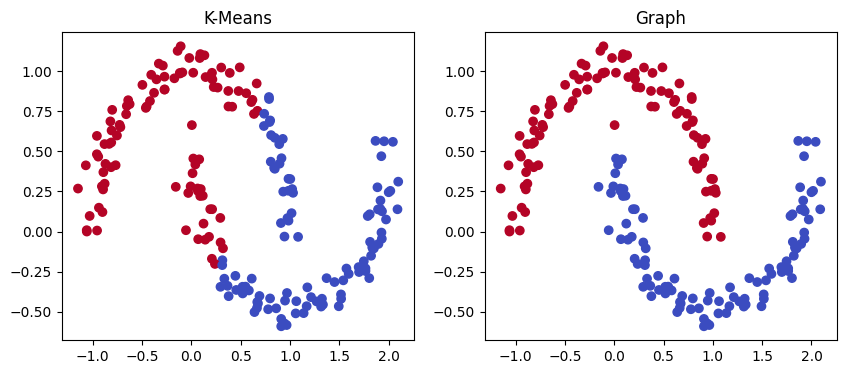

In [12]:
import random, math
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

X, _ = make_moons(n_samples=200, noise=0.07, random_state=42)
data = X.tolist()

def dist(a, b):
    return math.sqrt(sum((x - y) ** 2 for x, y in zip(a, b)))

def kmeans(pts, k, iters=50):
    random.seed(42)
    cents = random.sample(pts, k)
    for _ in range(iters):
        clusters = [[] for _ in range(k)]
        labels = []
        for p in pts:
            c = min(range(k), key=lambda i: dist(p, cents[i]))
            clusters[c].append(p)
            labels.append(c)
        cents = [[sum(x) / len(c) for x in zip(*c)] if c else random.choice(pts) for c in clusters]
    return labels

def graph_cluster(pts, k, sigma=0.15):
    n = len(pts)
    W = np.array([[math.exp(-(dist(pts[i], pts[j]) ** 2) / (2 * sigma ** 2)) if i != j else 0 for j in range(n)] for i in range(n)])
    L = np.diag(W.sum(axis=1)) - W
    _, vecs = np.linalg.eigh(L)
    return kmeans(vecs[:, :k].tolist(), k)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.scatter(X[:, 0], X[:, 1], c=kmeans(data, 2), cmap='coolwarm')
ax1.set_title("K-Means")

ax2.scatter(X[:, 0], X[:, 1], c=graph_cluster(data, 2), cmap='coolwarm')
ax2.set_title("Graph")
plt.show()